In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/imdb-india-movies/IMDb Movies India.csv


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
movie = pd.read_csv('/kaggle/input/imdb-india-movies/IMDb Movies India.csv', encoding='latin1')
movie.head()

,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
0,,NaN,NaN,Drama,NaN,NaN,J.S. Randhawa,Manmauji,Birbal,Rajendra Bhatia
1,#Gadhvi (He thought he was Gandhi),(2019),109 min,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid
2,#Homecoming,(2021),90 min,"Drama, Musical",NaN,NaN,Soumyajit Majumdar,Sayani Gupta,Plabita Borthakur,Roy Angana
3,#Yaaram,(2019),110 min,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor
4,...And Once Again,(2010),105 min,Drama,NaN,NaN,Amol Palekar,Rajat Kapoor,Rituparna Sengupta,Antara Mali


In [4]:
movie.shape

(15509, 10)

In [5]:
movie.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15509 entries, 0 to 15508
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      15509 non-null  object 
 1   Year      14981 non-null  object 
 2   Duration  7240 non-null   object 
 3   Genre     13632 non-null  object 
 4   Rating    7919 non-null   float64
 5   Votes     7920 non-null   object 
 6   Director  14984 non-null  object 
 7   Actor 1   13892 non-null  object 
 8   Actor 2   13125 non-null  object 
 9   Actor 3   12365 non-null  object 
dtypes: float64(1), object(9)
memory usage: 1.2+ MB


In [6]:
movie.isnull().sum()

Name           0
Year         528
Duration    8269
Genre       1877
Rating      7590
Votes       7589
Director     525
Actor 1     1617
Actor 2     2384
Actor 3     3144
dtype: int64

In [7]:
movie.drop_duplicates(inplace=True)

In [9]:
movie.isnull().sum()

Name           0
Year         527
Duration    8264
Genre       1876
Rating      7584
Votes       7583
Director     524
Actor 1     1615
Actor 2     2381
Actor 3     3140
dtype: int64

In [10]:
movie.dropna(inplace=True)

In [11]:
movie.shape

(5659, 10)

In [12]:
movie.describe(include='object')

,Name,Year,Duration,Genre,Votes,Director,Actor 1,Actor 2,Actor 3
count,5659,5659,5659,5659,5659,5659,5659,5659,5659
unique,5385,91,174,376,2027,2431,1960,2321,2556
top,Zindagi,(2019),120 min,Drama,7,David Dhawan,Amitabh Bachchan,Rekha,Pran
freq,4,227,169,844,90,41,104,52,57


In [13]:
movie['Year']= movie['Year'].str.strip("()").astype(int)
movie['Duration']=movie['Duration'].str.replace('min','').astype(int)
movie['Votes']=movie['Votes'].str.replace(',','').astype(int)

In [14]:
print('Year')
print(movie['Year'].unique())

Year
[2019 1997 2005 2012 2014 2004 2016 1991 2018 2010 1958 2021 2017 2009
 1993 2002 2008 1994 2007 2003 1998 1979 1974 2015 2006 1981 2020 1985
 2013 2011 1988 1987 1999 1973 1968 1982 1977 1950 1969 1948 1990 1989
 2001 2000 1953 1978 1963 1992 1976 1984 1986 1966 1975 1980 1967 1970
 1952 1972 1971 1964 1954 1962 1957 1965 1996 1995 1956 1955 1936 1983
 1951 1961 1959 1949 1960 1946 1940 1945 1938 1941 1942 1935 1937 1947
 1931 1933 1943 1944 1932 1939 1934]


In [15]:
print('Duration')
print(movie['Duration'].unique())

Duration
[109 110 147 142  82 116  96 120 161 166 102  87 132 105 146 168 158 126
  94 138 124 144 157 136 107 113  80 122 149 148 130 121 188 115 103 114
 170 100  99 140 128  93 125 145  75 111 134 104  92 137 127 119 135  90
 150 151  95 112 143 177 117 123  72 154 175 153  78 139 133 180  46 164
 162 171 160 152 163 165 141 129 156 240 172  88 155 167 106 193 108 195
 174  81 178  58 184  97 176 169 131  77  91  86  84 173 118 181 300  70
 101  79  65  48 183 159  83  68  89 201  64 186  74  85  98  49  60 207
  76 185  59 187 216  51  71  45  73  57 191 321 199 179  47 206  63 211
 247  56 213 210 190 223 189 224 202  69 255 197 182  66 214 208  21 200
 192  50  54 238  62  67  52 204 235 217  61 250]


In [16]:
print('Votes')
print(movie['Votes'].unique())

Votes
[    8    35   827 ... 70344   408  1496]


In [17]:
movie.dtypes

Name         object
Year          int64
Duration      int64
Genre        object
Rating      float64
Votes         int64
Director     object
Actor 1      object
Actor 2      object
Actor 3      object
dtype: object

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


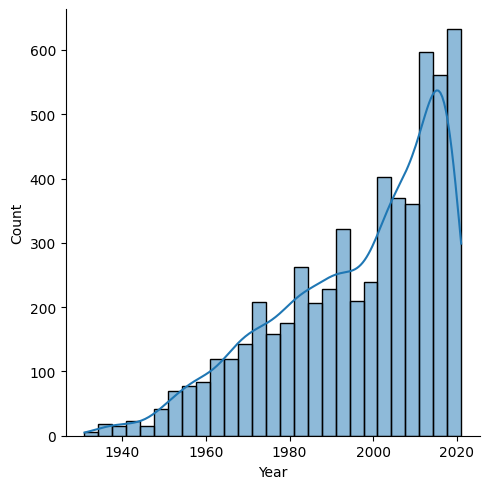

In [18]:
sns.displot(data=movie, x='Year', kde=True)

In [19]:
print(movie['Rating'].unique())

[ 7.   4.4  4.7  7.4  5.6  4.   6.2  5.9  6.5  5.7  6.3  7.2  6.6  7.3
  7.1  6.9  3.5  4.5  6.4  4.1  4.8  8.1  5.5  6.8  5.   6.1  7.7  5.1
  3.3  7.8  8.4  4.3  5.8  7.5  3.6  4.6  4.2  5.3  5.4  3.   8.   6.
  3.1  3.8  7.9  2.7  2.4  7.6  6.7  3.4  5.2  4.9  2.8  3.7  3.9  3.2
  2.9  8.2  8.7  8.3  9.3  8.8  2.1  2.5  2.3  8.5  8.6  2.6  1.7  9.
  1.4  8.9  1.9  9.4  9.7  1.8  9.2  2.   9.1 10.   1.6  2.2  1.1]


/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


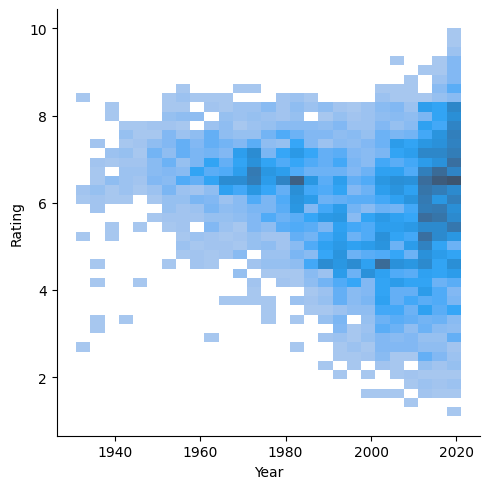

In [20]:
sns.displot(data=movie, x='Year',y='Rating')

<Axes: xlabel='Rating', ylabel='count'>

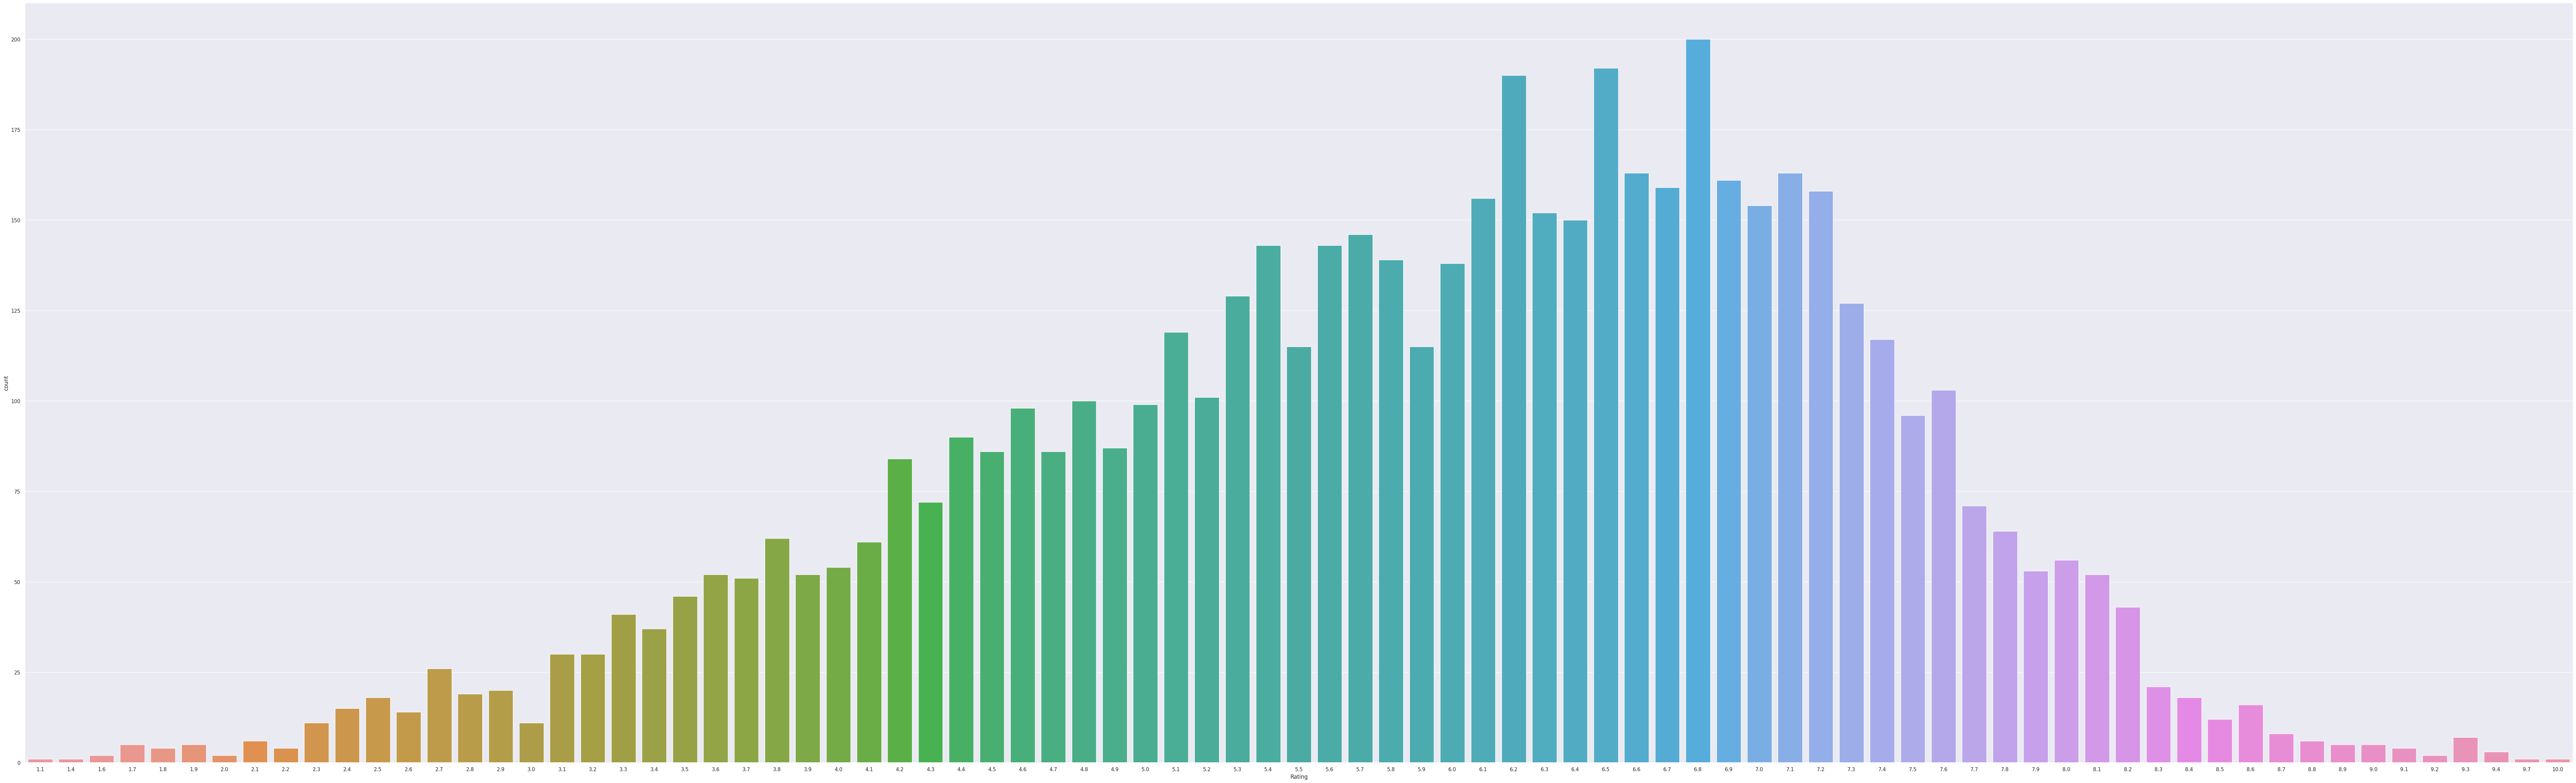

In [21]:
sns.set(rc={"figure.figsize":(100, 30)})
sns.countplot(data=movie, x='Rating')

In [22]:
print(movie['Director'].unique())

['Gaurav Bakshi' 'Ovais Khan' 'Rahul Rawail' ... 'Tariq Bhat'
 'Sumitra Bhave' 'Mozez Singh']


/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

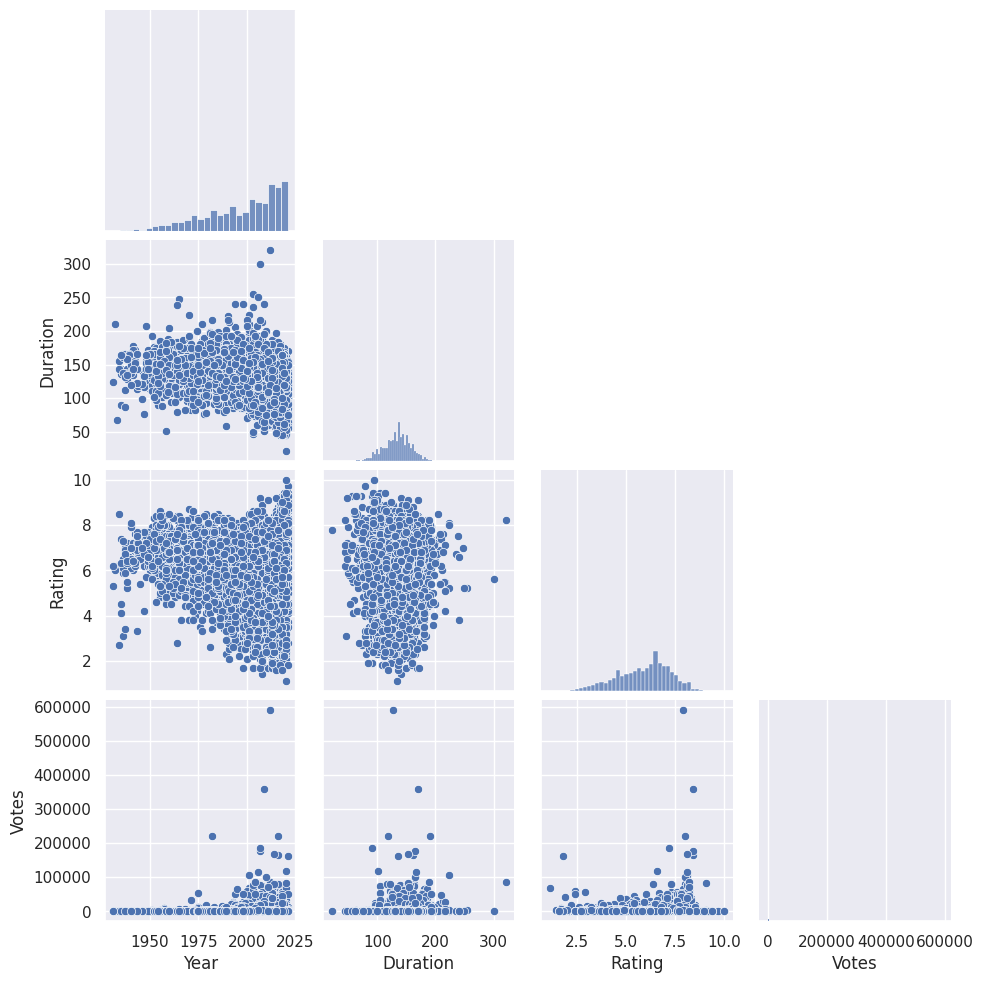

In [23]:
sns.pairplot(movie, corner=True)

In [24]:
movie.drop('Duration', axis=1, inplace=True)

In [25]:
movie.drop('Name', axis=1, inplace=True)

In [26]:
movie['Genre encoded'] = round(movie.groupby('Genre')['Rating'].transform('mean'),1)
movie['Votes encoded'] = round(movie.groupby('Votes')['Rating'].transform('mean'),1)
movie['Director encoded'] = round(movie.groupby('Director')['Rating'].transform('mean'),1)
movie['Actor 1 encoded'] = round(movie.groupby('Actor 1')['Rating'].transform('mean'),1)
movie['Actor 2 encoded'] = round(movie.groupby('Actor 2')['Rating'].transform('mean'),1)
movie['Actor 3 encoded'] = round(movie.groupby('Actor 3')['Rating'].transform('mean'),1)

movie.drop(columns=['Genre','Votes','Director','Actor 1','Actor 2','Actor 3'],inplace=True)
movie['Rating'] = round(movie['Rating'],1)
movie.head()

,Year,Rating,Genre encoded,Votes encoded,Director encoded,Actor 1 encoded,Actor 2 encoded,Actor 3 encoded
1,2019,7.0,6.4,5.6,7.0,6.8,7.0,7.0
3,2019,4.4,5.7,5.6,4.4,5.4,4.4,4.4
5,1997,4.7,6.2,4.8,5.3,4.8,5.8,5.9
6,2005,7.4,6.8,7.4,7.4,5.4,6.9,6.5
8,2012,5.6,5.5,6.6,5.6,5.6,5.9,5.6


In [27]:
x=movie.drop('Rating', axis=1)
y=movie['Rating']

In [28]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x, y, test_size=0.2)

In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

model=LinearRegression().fit(x_train,y_train)
y_pred=model.predict(x_test)

In [30]:
mse = mean_squared_error(y_pred,y_test)
from sklearn.metrics import r2_score
r2_score = r2_score(y_test, y_pred)

print("MSE for linear regression is : ",mse)
print("R2_score for linear regression is : ",r2_score)

MSE for linear regression is :  0.3196046882846157
R2_score for linear regression is :  0.8480156145652153


In [39]:
from sklearn.tree import DecisionTreeRegressor

model=DecisionTreeRegressor().fit(x_train,y_train)
y_pred=model.predict(x_test)

mse=mean_squared_error(y_test,y_pred)
from sklearn.metrics import r2_score
r2_score=r2_score(y_test,y_pred)

print("MSE for decision tree regression : ", mse)

print("R2_score for decision tree regression : ", r2_score)

MSE for decision tree regressor :  0.48962897526501764
R2_score for decision tree regressor :  0.7671624928403808


In [40]:
from sklearn.svm import SVR

model=SVR().fit(x_train,y_train)
y_pred=model.predict(x_test)

mse=mean_squared_error(y_test,y_pred)
from sklearn.metrics import r2_score
r2_score=r2_score(y_test,y_pred)

print("MSE for support vector regression : ", mse)

print("R2_score for support vector regression : ", r2_score)

MSE for support vector regression :  2.065211037675936
R2_score for decision tree regression :  0.017912308987178105


In [41]:
from sklearn.ensemble import RandomForestRegressor

model=RandomForestRegressor().fit(x_train,y_train)
y_pred=model.predict(x_test)

mse=mean_squared_error(y_test,y_pred)
from sklearn.metrics import r2_score
r2_score=r2_score(y_test,y_pred)

print("MSE for random forest regression : ", mse)

print("R2_score for random forest regression : ", r2_score)

MSE for random forest regression :  0.27012572526501766
R2_score for random forest regression :  0.8715447743746212


In [42]:
from sklearn.ensemble import GradientBoostingRegressor

model=GradientBoostingRegressor().fit(x_train,y_train)
y_pred=model.predict(x_test)

mse=mean_squared_error(y_test,y_pred)
from sklearn.metrics import r2_score
r2_score=r2_score(y_test,y_pred)

print("MSE for gradient boosting regression : ", mse)

print("R2_score for gradient boosting regression : ", r2_score)

MSE for gradient boosting regression :  0.2796240797747322
R2_score for gradient boosting regression :  0.8670279395917875


In [43]:
from sklearn.ensemble import AdaBoostRegressor

model=AdaBoostRegressor().fit(x_train,y_train)
y_pred=model.predict(x_test)

mse=mean_squared_error(y_test,y_pred)
from sklearn.metrics import r2_score
r2_score=r2_score(y_test,y_pred)

print("MSE for adaptive boosting regression : ", mse)

print("R2_score for adaptive boosting regression : ", r2_score)

MSE for adaptive boosting regression :  0.4207084158839747
R2_score for adaptive boosting regression :  0.7999368833462588


In [44]:
from xgboost import XGBRegressor

model=XGBRegressor().fit(x_train,y_train)
y_pred=model.predict(x_test)

mse=mean_squared_error(y_test,y_pred)
from sklearn.metrics import r2_score
r2_score=r2_score(y_test,y_pred)

print("MSE for extreme gradient boosting regression : ", mse)

print("R2_score for extreme gradient boosting regression : ", r2_score)

MSE for extreme gradient boosting regression :  0.27879053632823836
R2_score for extreme gradient boosting regression :  0.8674243217260061
